In [ ]:
%load_ext autoreload 
%autoreload 2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 25)
import sys
sys.path.insert(0, '..')
# module viz is only containing my plot settings for this part.
# imported due to way to long to add directly to a notebook.
from src import viz



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Ladda och kontrollera datakvalité  

In [6]:
df = pd.read_csv('../data/health_study_dataset.csv', index_col='id')
df = df.astype({'sex': 'category','smoker': 'category'})
# adds bmi column to the dataframe
df['bmi'] = df['weight'] / (df['height'] / 100) ** 2
print(df.head(3))
print('\nInfo:\n')
df.info()
print('\nMissing Values:\n', df.isna().sum())
print('\nduplicates:', df.duplicated().sum())

    age sex  height  weight  systolic_bp  cholesterol smoker  disease        bmi
id                                                                              
1    57   F   168.9    65.8        141.8         4.58     No        0  23.065698
2    47   M   180.4    95.9        144.8         5.18    Yes        0  29.467653
3    59   F   169.9    82.2        151.7         6.16     No        0  28.476398

Info:

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 1 to 800
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   age          800 non-null    int64   
 1   sex          800 non-null    category
 2   height       800 non-null    float64 
 3   weight       800 non-null    float64 
 4   systolic_bp  800 non-null    float64 
 5   cholesterol  800 non-null    float64 
 6   smoker       800 non-null    category
 7   disease      800 non-null    int64   
 8   bmi          800 non-null    float64 
dtypes: category(2), 

- inga null-värden hittades
- inga dubletter hittades  
- Jag har satt index till id, och lagt till bmi som kolumn för bättre värde av kroppsbyggnad än längd och vikt för sig.  
- Ändrat sex and smoker till `category` datatyp

#### Rimlighetskontroll av hälsovärden
För att identifiera potentiellt orimliga värden har jag jämfört datasetets observationer med medicinsk information och rekommenderade gränsvärden från 1177 Vårdguiden.  
Gränsvärdena används som stöd vid bedömningen av avvikande observationer. Det är viktigt att skilja mellan medicinskt avvikande värden och faktiskt orimliga mätvärden, eftersom extrema hälsovärden kan förekomma i verkligheten.  
Information om medicinska gränsvärden och hälsorelaterade mått har hämtats från [1177 Vårdguiden](https://www.1177.se/).  

- 12  < BMI eller > 50
- 50  < Systoliskt blodtryck (mmHg) eller > 250
- 1.0 < Kolesterol (mmol/L) eller > 10.0

Gränserna är avsedda att fånga potentiellt orimliga mätvärden, inte medicinskt avvikande värden och är mina egna valda gränser för just rimlighetskontroll.

In [7]:
print(f"Antal individer med BMI < 12 eller > 50: {((df['bmi'] < 12) | (df['bmi'] > 50)).sum()}")
print(f"Antal individer med systoliskt blodtryck (mmHg) < 50 eller > 250: {((df["systolic_bp"] < 50) | (df['systolic_bp'] > 250)).sum()}")
print(f"Antal individer med kolesterol (mmol/L) < 1.0 eller > 10.0: {((df['cholesterol'] < 1.0) | (df['cholesterol'] > 10.0)).sum()}")

print('\nDescription:\n', df.describe().round(2))

Antal individer med BMI < 12 eller > 50: 0
Antal individer med systoliskt blodtryck (mmHg) < 50 eller > 250: 0
Antal individer med kolesterol (mmol/L) < 1.0 eller > 10.0: 0

Description:
           age  height  weight  systolic_bp  cholesterol  disease     bmi
count  800.00  800.00  800.00       800.00       800.00   800.00  800.00
mean    49.43  171.85   73.41       149.18         4.93     0.06   24.93
std     14.50    9.80   13.69        12.79         0.85     0.24    4.66
min     18.00  144.40   33.70       106.80         2.50     0.00   12.63
25%     39.00  164.78   64.80       140.90         4.33     0.00   21.92
50%     50.00  171.35   73.20       149.40         4.97     0.00   24.70
75%     59.00  178.92   82.60       157.60         5.48     0.00   28.01
max     90.00  200.40  114.40       185.90         7.88     1.00   40.14


Inga orimliga värden hittades och samtliga min, maxvärden ser rimliga ut i tabellen.

#### Spridning

In [8]:
summary = pd.DataFrame({
    'Mean': [df['age'].mean(), df['weight'].mean(), df['height'].mean(), df['systolic_bp'].mean(), df['cholesterol'].mean()],
    'Median': [df['age'].median(), df['weight'].median(), df['height'].median(), df['systolic_bp'].median(), df['cholesterol'].median()],
    'Min': [df['age'].min(), df['weight'].min(), df['height'].min(), df['systolic_bp'].min(), df['cholesterol'].min()],
    'Max': [df['age'].max(), df['weight'].max(), df['height'].max(), df['systolic_bp'].max(), df['cholesterol'].max()]
}, index=['Age', 'Weight', 'Height', 'Systolic BP', 'Cholesterol'])

print(summary.round(2))


               Mean  Median    Min     Max
Age           49.43   50.00   18.0   90.00
Weight        73.41   73.20   33.7  114.40
Height       171.85  171.35  144.4  200.40
Systolic BP  149.18  149.40  106.8  185.90
Cholesterol    4.93    4.97    2.5    7.88


Medelvärden och median ligger väldigt nära varandra för de undersökta variablerna, vilket indikerar relativt symmetriska fördelningar.  
Spridningen ser ut att vara ganska stor i alla variabler.


# Korrelationer
Korrelationsanalysen har genomförts med Pandas `DataFrame.corr()`, som stöder Pearson, Spearman och Kendall.
([Pandas documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)).  
Samtliga tre metoder har testats för att jämföra hur valet av korrelationsmetod påverkar resultaten. Pearson valdes som huvudsaklig metod för den fortsatta analysen.

In [9]:
corr_pearson = df.select_dtypes(include='number').corr(method='pearson')
corr_spearman = df.select_dtypes(include='number').corr(method='spearman')
corr_kendall = df.select_dtypes(include='number').corr(method='kendall')

print('Korrelation pearson:\n',corr_pearson)
print('\nKorrelation spearman:\n',corr_spearman)
print('\nKorrelation kendall:\n',corr_kendall)

Korrelation pearson:
                   age    height    weight  systolic_bp  cholesterol   disease       bmi
age          1.000000 -0.004653 -0.017309     0.607578     0.491173  0.021629 -0.011153
height      -0.004653  1.000000  0.320260     0.086297    -0.043344  0.033194 -0.295205
weight      -0.017309  0.320260  1.000000     0.179467     0.256214  0.037424  0.803614
systolic_bp  0.607578  0.086297  0.179467     1.000000     0.368441  0.031059  0.128814
cholesterol  0.491173 -0.043344  0.256214     0.368441     1.000000  0.013729  0.292370
disease      0.021629  0.033194  0.037424     0.031059     0.013729  1.000000  0.018864
bmi         -0.011153 -0.295205  0.803614     0.128814     0.292370  0.018864  1.000000

Korrelation spearman:
                   age    height    weight  systolic_bp  cholesterol   disease       bmi
age          1.000000  0.010457 -0.016044     0.588435     0.478501  0.017659 -0.024225
height       0.010457  1.000000  0.330980     0.093239    -0.036082  0.034

En jämförelse mellan Pearson och Spearman visar mycket likartade korrelationsvärden för de undersökta variablerna. Detta tyder på att de identifierade sambanden inte är särskilt känsliga för valet mellan metoderna.
Kendall ger genomgående lägre koefficienter, vilket beror på att metoden använder en annan beräkningsgrund och skala. De övergripande slutsatserna om sambandens riktning kvarstår dock.

- Det finns korrelationer mellan ålder och blodtryck/kolesterol (ett förväntat resultat), men ingenting som verkar påverka sjukdomsrisk med ett tydligt linjärt samband.

- Datan visar även på måttlig korrelation mellan kolesterol och blodtryck vilket är ett förväntat resultat men kan undersökas vidare om det skiljer mellan olika grupper.

##### Val av färgpalett

I rapportens diagram används färgpaletten Okabe-Ito. Den valdes eftersom den är utformad för att färgerna ska vara lättare att särskilja för personer med olika former av färgseendedefekter.  
Detta bidrar till ökad tillgänglighet och gör diagrammen lättare att tolka för en bredare läsarkrets.   
Det blir särskilt relevant eftersom rapporten behandlar medicinska data.  
https://jfly.uni-koeln.de/color/ (Okabe & Ito, 2008). 
Jag har valt att ändra färgernas ursprungliga ordning för att skapa större variation mellan ljusa och mörka toner i diagrammen. Gult och svart har jag placerat sist i paletten för att få en mer konsekvent visuell balans.  
Läs mer om min policy här: [Data Visualization Policy](../visualization_policy.md).  

# Demografisk beskrivning

In [10]:
disease_share = (df['disease'].map({0: 'Ingen sjukdom', 1: 'Sjukdom'}).value_counts(normalize=True) * 100)
print('Andel sjukdom vs ingen sjukdom (%):\n\n',disease_share.round(2).to_string())

age_by_sex = df.groupby('sex').agg(
    mean_age=('age', 'mean'),
    median_age=('age', 'median'),
    std_age=('age', 'std'),
    count=('age', 'count'))

print('\nÅldersfördelning mellan könen:\n\n',age_by_sex.round(1))

Andel sjukdom vs ingen sjukdom (%):

 disease
Ingen sjukdom    94.12
Sjukdom           5.88

Åldersfördelning mellan könen:

      mean_age  median_age  std_age  count
sex                                      
F        49.9        50.0     14.5    403
M        49.0        49.0     14.5    397


#### Histogram/KDE över ålder
- Visar populationens sammansättning och skillnader mellan män och kvinnors åldersfördelning i populationen.

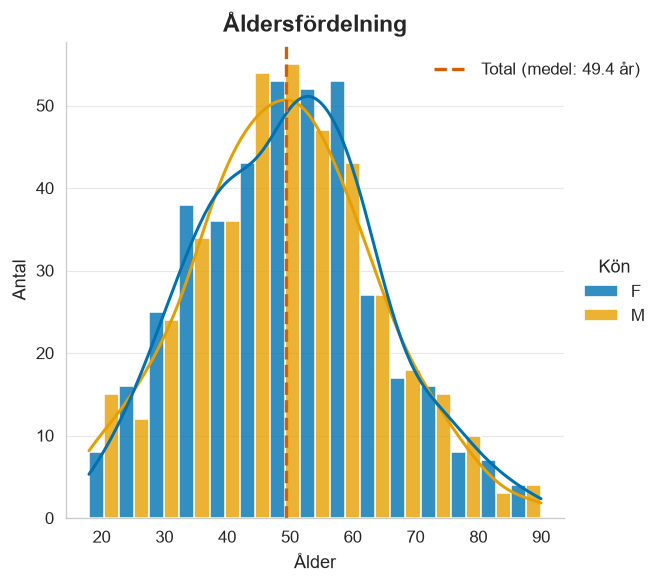

In [12]:
dis_plot_age = sns.displot(data=df, x='age', hue='sex', kde=True, bins=15, palette=viz.okabe_ito[:2], alpha=0.8, multiple='dodge')

mean_age = df['age'].mean()
dis_plot_age.ax.axvline(mean_age, color=viz.okabe_ito[4], linestyle='--', linewidth=2, label=f'Total (medel: {mean_age:.1f} år)')

dis_plot_age.legend.set_title('Kön')
plt.title('Åldersfördelning')
plt.xlabel('Ålder')
plt.ylabel('Antal')
plt.legend(loc='upper left', bbox_to_anchor=(0.7, 1.0))
plt.tight_layout()
plt.show()

Åldersfördelningen är relativt lika mellan män och kvinnor och uppvisar en ungefärlig normalfördelning.  
Diagrammet ger inga tydliga indikationer på större skillnader mellan könen.

# Hälsotillstånd

#### Histogram/KDE över blodtryck	
- Fördelningen av blodtryck	Identifierar spridning och extremvärden

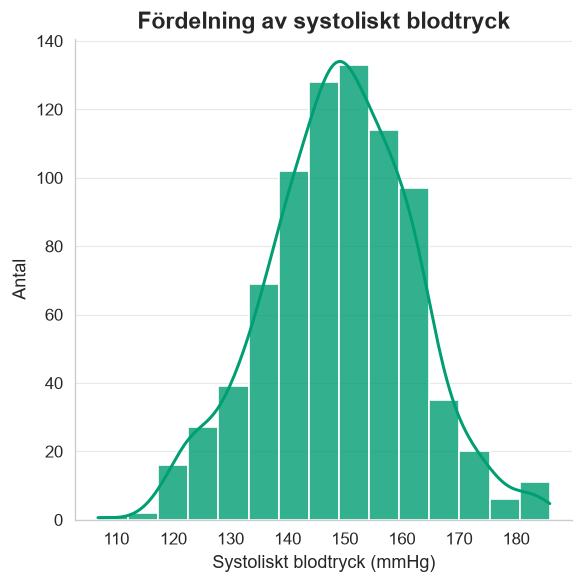

In [13]:
dis_plot_sys = sns.displot(data=df, x='systolic_bp', kde=True, bins=15, color=viz.okabe_ito[2], alpha=0.8)

plt.title('Fördelning av systoliskt blodtryck')
plt.xlabel('Systoliskt blodtryck (mmHg)')
plt.ylabel('Antal')
plt.tight_layout()
plt.show()

Fördelningen är relativt jämn, men uppvisar en viss högerskevhet.  
Ligger nära en normalfördelning, även om en viss asymmetri kan urskiljas.

#### Stapeldiagram för antal rökare fördelat på kön
(med kompletterande tabell för andel)

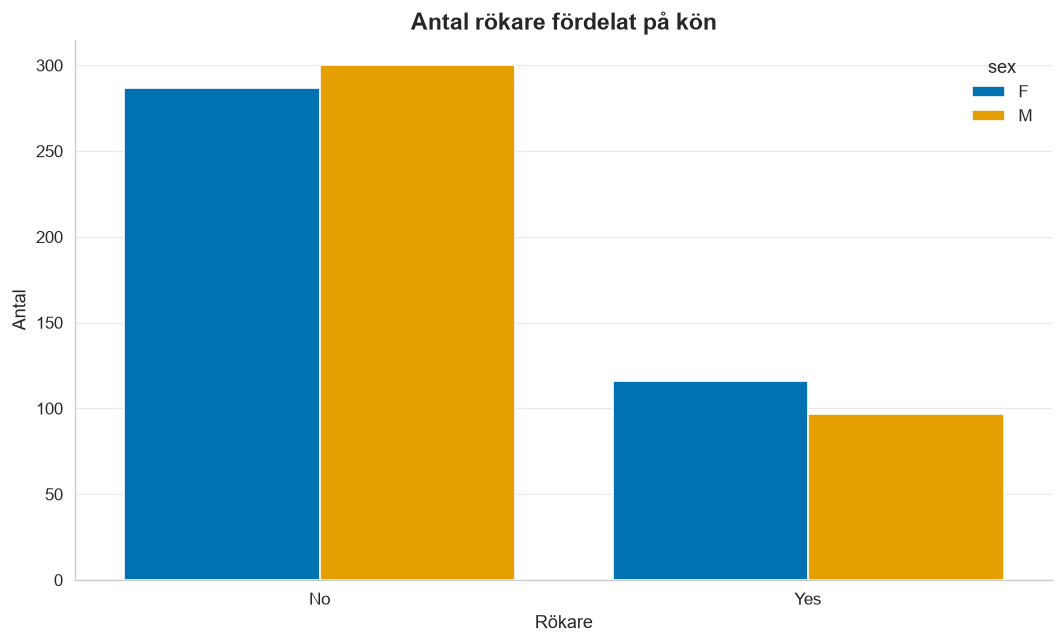

Andel rökare i (%) fördelat på kön:
 smoker    No   Yes
sex               
F       71.2  28.8
M       75.6  24.4


In [14]:
sns.countplot(x='smoker',data=df, palette=viz.okabe_ito[:2], hue='sex', saturation=1)
plt.title('Antal rökare fördelat på kön')
plt.xlabel('Rökare')
plt.ylabel('Antal')
plt.tight_layout()
plt.show()

smoker_share = pd.crosstab(
    df['sex'],
    df['smoker'],
    normalize='index') * 100
print('Andel rökare i (%) fördelat på kön:\n', smoker_share.round(1))

Visar på en liten överrepresentation av kvinnor som röker i datasetet.

#### Kolesterol – blodtryck	
- Finns det ett samband mellan högt kolesterol och högt blodtryck?  
Värt att undersöka vidare då korrelationstabellen visade på en svag till måttlig korrelation.  
Diagrammet nedan visar även på en viss skillnad mellan män och kvinnor.

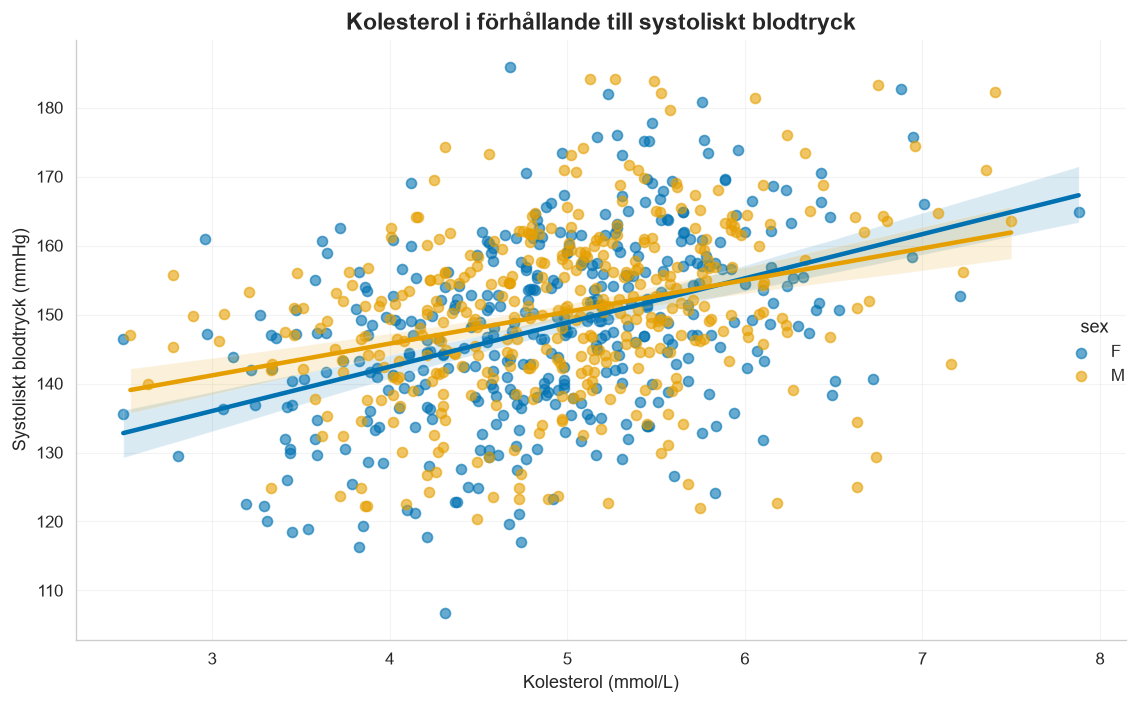

Korrelation mellan kolesterol och systoliskt blodtryck uppdelat efter kön:
sex             
F    systolic_bp    0.411753
M    systolic_bp    0.317401


In [16]:
sns.lmplot(data=df, x='cholesterol', y='systolic_bp', hue='sex', palette=viz.okabe_ito[:2], scatter_kws={'alpha': 0.6}, height=6, aspect=1.5)

plt.title('Kolesterol i förhållande till systoliskt blodtryck')
plt.xlabel('Kolesterol (mmol/L)')
plt.ylabel('Systoliskt blodtryck (mmHg)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Korrelation mellan kolesterol och systoliskt blodtryck uppdelat efter kön:\n{df.groupby('sex')[['cholesterol', 'systolic_bp']].corr().iloc[[1, 3],0].to_string()}')

Resultatet visar en svag till måttlig positiv korrelation mellan kolesterol och systoliskt blodtryck i hela datasetet (Pearsons r = 0.368).   
Sambandet verkar vara något starkare för kvinnor (r = 0.412) än för män (r = 0.317).  

Konfidensintervallen för regressionslinjerna överlappar, vilket tyder på att det inte finns någon tydlig skillnad mellan gruppernas skattade samband.   
Diagrammet ger dock inte tillräckligt underlag för att avgöra om skillnaden är statistiskt signifikant.  

Det kan vara intressant att undersöka om skillnaden kvarstår efter kontroll för exempelvis ålder, eller om den kan förklaras av skillnader i andra faktorer, såsom rökvanor mellan könen då vi tidigare visat att det finns en liten överrepresentation av rökning hos kvinnor i datasetet.

# Undersökning av sjukdomsrisk
#### A. Blodtryck uppdelat efter sjukdom

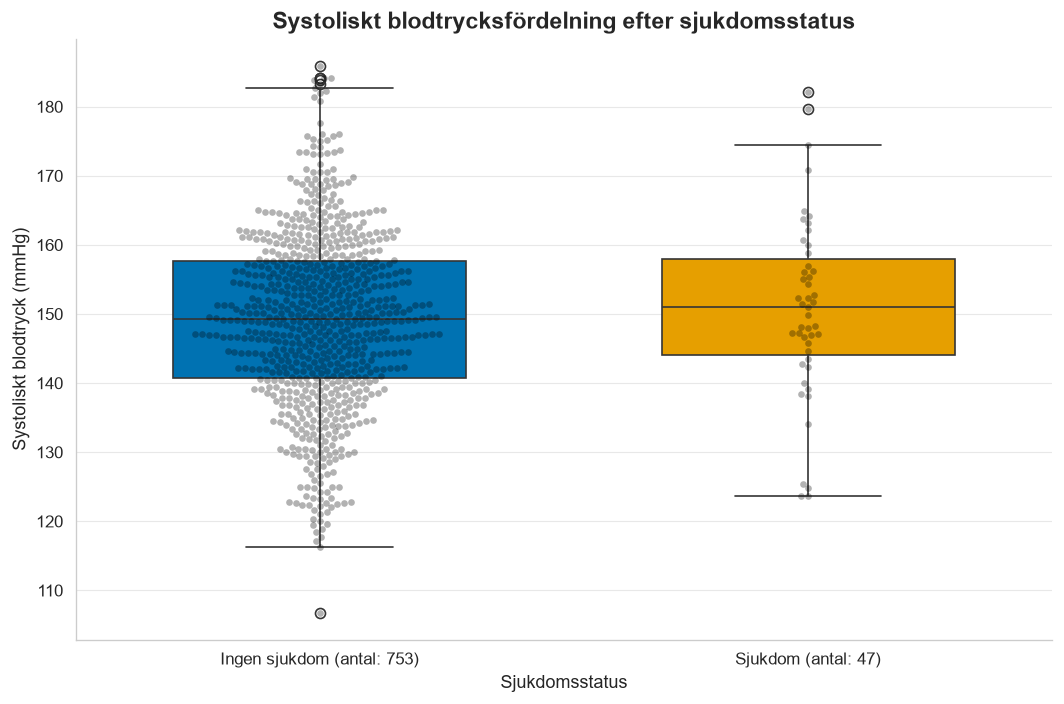

In [15]:
disease_counts = df['disease'].value_counts()
labels = {0: f'Ingen sjukdom (antal: {disease_counts.get(0, 0)})',
        1: f'Sjukdom (antal: {disease_counts.get(1, 0)})'}

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='systolic_bp',hue='disease',palette=viz.okabe_ito[:2],legend=False, ax=ax, width=0.6, saturation=1)
sns.swarmplot(data=df,x='disease',y='systolic_bp',color=viz.okabe_ito[7],alpha=0.3,size=4,ax=ax)
plt.title('Systoliskt blodtrycksfördelning efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Systoliskt blodtryck (mmHg)')
plt.xticks([0, 1], [labels[0], labels[1]])
plt.tight_layout()
plt.show()

Fördelningen av systoliskt blodtryck uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.   
Medianvärden och spridning verkar vara relativt lika.  
 Den mindre gruppens värden ryms till stor del inom variationsintervallet för den större gruppen i detta dataset och finns därför inget tydligt visuellt stöd för ett samband mellan systoliskt blodtryck och sjukdomsstatus.

#### B. Kolesterol uppdelat efter sjukdom

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='cholesterol',hue='disease',palette=viz.okabe_ito[:2],legend=False, ax=ax, width=0.6, saturation=1)
sns.swarmplot(data=df,x='disease',y='cholesterol',color=viz.okabe_ito[7],alpha=0.3,size=4,ax=ax)
plt.title('Fördelning av kolesterol efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Kolesterol (mmol/L)')
plt.xticks([0, 1], [labels[0], labels[1]])
plt.tight_layout()
plt.show()

Fördelningen av kolesterol uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.   
Medianvärden och spridning verkar vara relativt lika.  
Den mindre gruppens värden ryms till stor del inom variationsintervallet för den större gruppen i detta dataset och finns därför inget tydligt visuellt stöd för ett samband mellan kolesterol och sjukdomsstatus.

#### C. Ålder uppdelat efter sjukdomsstatus

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='age',hue='disease',palette=viz.okabe_ito[:2],legend=False, ax=ax, width=0.6)

sns.swarmplot(data=df,x='disease',y='age',color=viz.okabe_ito[7],alpha=0.3,size=4,ax=ax)
plt.xticks([0, 1], [labels[0], labels[1]])

plt.title('Åldersfördelning efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Ålder (år)')
plt.show()

Åldersfördelningen uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.   
Medianvärden och spridning verkar vara relativt lika.  
Den mindre gruppens värden ryms till stor del inom variationsintervallet för den större gruppen i detta dataset och finns därför inget tydligt visuellt stöd för ett samband mellan ålder och sjukdomsstatus.

#### D. Sjukdomsförekomst bland rökare och icke-rökare

In [ ]:
smoker_proportion = pd.crosstab(df['disease'],df['smoker'], normalize='index').reindex(columns=['No', 'Yes']) * 100
disease_counts = df['disease'].value_counts()

labels = [f'Ingen sjukdom (n={disease_counts.get(0, 0)})',f'Sjukdom (n={disease_counts.get(1, 0)})']
smoker_proportion.index = labels

ax = smoker_proportion.plot(kind='bar', stacked=True, color=[okabe_ito[0], okabe_ito[1]], figsize=(9, 6), alpha = 1)

ax.set_title('Sjukdomsförekomst efter rökstatus')
ax.set_xlabel('Sjukdomsstatus')
ax.set_ylabel('Andel deltagare (%)')
ax.set_ylim(0, 110)
ax.legend(['Icke-rökare', 'Rökare'],title='Rökstatus')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

smoker_risk = pd.crosstab(
    df['smoker'],
    df['disease'],
    normalize='index'
) * 100
smoker_risk.columns = ['Ingen sjukdom', 'Sjukdom']
print('Fördelning av rökare med och utan sjukdom:\n', smoker_risk)

Andelen rökare är högre bland individer med sjukdom än bland individer utan sjukdom.  
Detta indikerar ett möjligt samband mellan rökning som riskfaktor och sjukdomsstatus.

# Simulerad sjukdomsförekomst

In [ ]:
disease_probability = df['disease'].mean()
print(f"Observad sjukdomsförekomst: {disease_probability:.2%}")

- Sannolikhet för sjukdom: probability = 0.0588
- Sannolikhet för ingen sjukdom: 1 - probability = 0.9412
- Simulerad population: 1 000 individer
- Förväntat antal individer med sjukdom: cirka 59 st av 1000

In [ ]:
rng = np.random.default_rng(0)
# skapar en simulerad population på 1000 utifrån 1 och 0 som alternativ, p =  är disease_probability (p står för probability, inte p-värde här) 
simulated_population = rng.choice([0, 1], size=1000, p=[1-disease_probability, disease_probability])

simulated_prevalence = simulated_population.mean()

print(f"Simulerad sjukdomsförekomst:  {simulated_prevalence:.2%}")
print(f"Observerad sjukdomsförekomst: {disease_probability:.2%}")
print(f"Skillnad:                     {abs(disease_probability - simulated_prevalence):.2%}")

Den simulerade sjukdomsförekomsten ligger nära den observerade sjukdomsförekomsten i originaldatasetet.  
Den mindre skillnaden mellan resultaten beror på slumpmässig variation i simuleringen, eftersom varje individ tilldelas en sjukdomsstatus slumpmässigt baserat på den observerade sannolikheten.  
Slumpfröet säkerställer att simuleringen ger samma resultat varje gång koden körs.

# **KOD OCH TEXT ÄR HELT KONTROLLERAD HIT**

# Konfidensintervall för systoliskt blodtryck
Normalapproximation och bootstrap, med 95% konfidensnivå.

#### Stickprovsmedelvärde och standardavvikelse

In [ ]:
systolic_mean = df['systolic_bp'].mean()
systolic_std = df['systolic_bp'].std(ddof=1)

print('Medelvärde för observerat systoliskt blodtryck (mmHg):', systolic_mean.round(2))
print('Standardavvikelse för observerat systoliskt blodtryck (mmHg):', systolic_std.round(2))

### Konfidensintervall med normalapproximation

In [ ]:
n = df['systolic_bp'].count()
z = 1.96

standard_error = systolic_std / np.sqrt(n)
margin_of_error = z * standard_error

ci_lower = systolic_mean - margin_of_error
ci_upper = systolic_mean + margin_of_error

print(f'95 % konfidensintervall: [{ci_lower:.2f}, {ci_upper:.2f}] mmHg')

95 % konfidensintervallet visar att populationens genomsnittliga systoliska blodtryck uppskattas ligga mellan 148,29 och 150,07 mmHg. Det relativt smala intervallet tyder på en god precision i skattningen.

### Konfidensintervall med bootstrap

In [ ]:
np.random.seed(0)

n_bootstrap = 10_000
bootstrap_means = []

for _ in range(n_bootstrap):
    sample = df['systolic_bp'].sample(n=n, replace=True)
    bootstrap_means.append(sample.mean())

ci_bootstrap_lower = np.percentile(bootstrap_means, 2.5)
ci_bootstrap_upper = np.percentile(bootstrap_means, 97.5)

print(f'95 % bootstrap-konfidensintervall: [{ci_bootstrap_lower:.2f}, {ci_bootstrap_upper:.2f}] mmHg')

Det relativt smala intervallet tyder på att skattningen av populationens genomsnittliga systoliska blodtryck har god precision.  
Bootstrap ger här ett resultat som ligger mycket nära normalapproximationens resultat.

## Jämförelse och metodval

De två metoderna gav nästan identiska resultat.  
Normalapproximationen gav konfidensintervallet **[148,29, 150,07] mmHg**, medan bootstrap gav **[148,29, 150,06] mmHg**. Skillnaden är endast 0,01 mmHg i den övre gränsen och har ingen praktisk betydelse i denna undersökning.

Normalapproximationen beräknar intervallet utifrån stickprovsmedelvärdet och standardfelet, med ett kritiskt z-värde. Metoden ger ett symmetriskt intervall runt stickprovsmedelvärdet. Bootstrap bygger i stället på upprepade omsamplingar med återläggning och använder percentilerna i fördelningen av bootstrap-medelvärdena. Det innebär att bootstrapintervallet inte behöver vara symmetriskt.  
Antalet omsamplingar sattes till 10 000 för att få en stabil uppskattning av bootstrapfördelningen och konfidensintervallets gränser (Hesterberg, 2015). [Bootstrap – How Many Bootstrap Samples](https://people.stat.sc.edu/hoyen/PastTeaching/STAT704-2022/Notes/Bootstrap.pdf)

Eftersom stickprovet är stort (n = 800) är normalapproximationen lämplig för att uppskatta medelvärdet, förutsatt att observationerna är oberoende och stickprovet är representativt. Bootstrap fungerar som en kompletterande metod och ger här ett resultat som ligger mycket nära normalapproximationens resultat.

Jag väljer därför normalapproximationen som huvudmetod eftersom den är enklare att beräkna och ger i princip samma resultat. Bootstrap är ändå värdefull som jämförelse.

# Hypotesprövning för blodtryck hos rökare

### Referenser

- 1177 Vårdguiden. (u.å.). https://www.1177.se/  
- Pandas. (u.å.). *DataFrame.corr()*.  https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html  
- Okabe, M., & Ito, K. (2008). *Color Universal Design (CUD): How to Make Figures and Presentations That Are Friendly to Colorblind People.* https://jfly.uni-koeln.de/color/  
- Hesterberg, T. (2015). *What Teachers Should Know About the Bootstrap*. 
[PDF](https://people.stat.sc.edu/hoyen/PastTeaching/STAT704-2022/Notes/Bootstrap.pdf)  